<a href="https://colab.research.google.com/github/Chauhanrajk007/ml-training/blob/main/titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSurvival distribution:")
print(df["Survived"].value_counts())

print("\nStatistical summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          6

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
# Select useful features
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

X = df[features].copy()
y = df["Survived"].copy()

# Fill missing numerical values
X["Age"] = X["Age"].fillna(X["Age"].median())
X["Fare"] = X["Fare"].fillna(X["Fare"].median())

# Fill missing categorical values
X["Embarked"] = X["Embarked"].fillna(X["Embarked"].mode()[0])

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, columns=["Sex", "Embarked"], dtype=int)

print("Preprocessing completed!")
display(X.head())

print("Features:", list(X.columns))

Preprocessing completed!


,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,1,0,0
2,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,35.0,1,0,53.1000,1,0,0,0,1
4,3,35.0,0,0,8.0500,0,1,0,0,1


Features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 712
Testing samples: 179


In [6]:
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

print("Training started...")

model.fit(X_train, y_train)

print("Training completed successfully!")

Training started...
Training completed successfully!


In [7]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Did Not Survive", "Survived"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 81.56%

Classification Report:
                 precision    recall  f1-score   support

Did Not Survive       0.82      0.89      0.86       110
       Survived       0.80      0.70      0.74        69

       accuracy                           0.82       179
      macro avg       0.81      0.79      0.80       179
   weighted avg       0.81      0.82      0.81       179


Confusion Matrix:
[[98 12]
 [21 48]]


,Feature,Importance
4,Fare,0.228266
1,Age,0.212868
5,Sex_female,0.182440
6,Sex_male,0.158263
0,Pclass,0.088752
2,SibSp,0.049269
3,Parch,0.041186
9,Embarked_S,0.016612
7,Embarked_C,0.014276
8,Embarked_Q,0.008069


<Axes: title={'center': 'Titanic Survival - Feature Importance'}, xlabel='Feature', ylabel='Importance'>

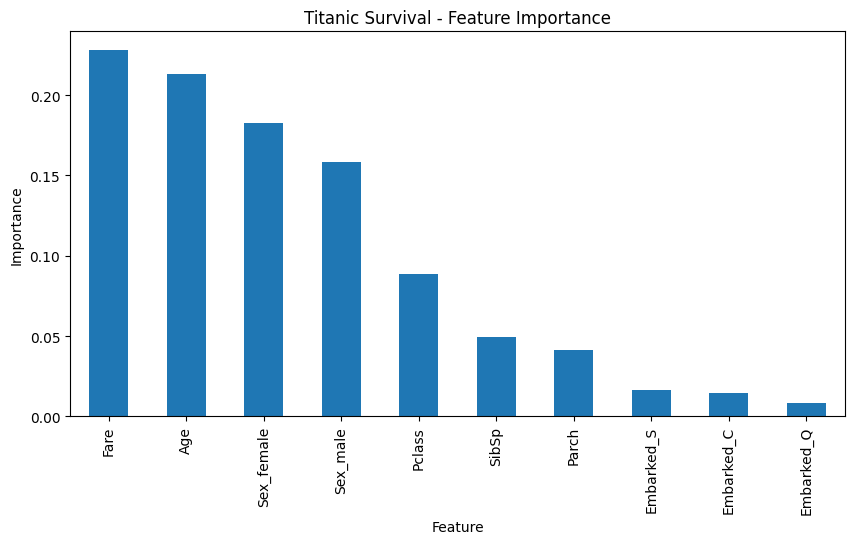

In [8]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(importance)

importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False,
    title="Titanic Survival - Feature Importance",
    ylabel="Importance",
    figsize=(10, 5)
)

In [9]:
# Example passenger
new_passenger = pd.DataFrame([{
    "Pclass": 3,
    "Age": 22,
    "SibSp": 1,
    "Parch": 0,
    "Fare": 7.25,
    "Sex_female": 0,
    "Sex_male": 1,
    "Embarked_C": 0,
    "Embarked_Q": 0,
    "Embarked_S": 1
}])

# Ensure columns match the training data
new_passenger = new_passenger.reindex(columns=X.columns, fill_value=0)

prediction = model.predict(new_passenger)[0]
probabilities = model.predict_proba(new_passenger)[0]

print("Prediction:", "Survived" if prediction == 1 else "Did not survive")
print(f"Probability of not surviving: {probabilities[0] * 100:.2f}%")
print(f"Probability of surviving: {probabilities[1] * 100:.2f}%")

Prediction: Did not survive
Probability of not surviving: 83.94%
Probability of surviving: 16.06%


In [10]:
import joblib

joblib.dump(model, "titanic_model.pkl")
joblib.dump(list(X.columns), "titanic_features.pkl")

print("Model saved as titanic_model.pkl")
print("Features saved as titanic_features.pkl")

Model saved as titanic_model.pkl
Features saved as titanic_features.pkl
